<img src="images/nvidia_header.png" style="margin-left: -30px; width: 300px; float: left;">

# Accelerating Clustering Algorithms to Achieve the Highest Performance #

## Part 6: Exercises ##

**Table of Contents**
<br>
This notebook provides an opportunity to practice clustering on a real-world dataset. This notebook covers the below sections: 

1. [Initial Envrionment Set Up](#Initial-Envrionment-Set-Up)
2. [Data Loading](#Data-Loading)
3. [Data Preprocessing](#Data-Preprocessing)
4. [Embedding](#Embedding)
5. [Dimensionality Reduction](#Dimensionality-Reduction)
6. [Export the DataFrame](#Export-the-DataFrame)
7. [Import the Data](#Import-the-Data)
8. [cuML K-Means](#cuML-K-Means)
9. [cuML HDBSCAN](#cuML-HDBSCAN)

## Initial Environment Set Up

In [1]:
%load_ext cudf.pandas

In [2]:
import pandas as pd
# Sample operation
cudf_df = pd.DataFrame({'a': [1, 2, 3], 'b': [4, 5, 6]})
cudf_df.info()

<class 'cudf.core.dataframe.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   a       3 non-null      int64
 1   b       3 non-null      int64
dtypes: int64(2)
memory usage: 48.0 bytes


In [3]:
import cupy as cp
# Sample operation
guess_ages = cp.zeros((2,3))
type(guess_ages)

cupy.ndarray

## Data Loading

In [4]:
from datasets import load_dataset

dataset = load_dataset("McAuley-Lab/Amazon-Reviews-2023", "raw_review_All_Beauty", trust_remote_code=True)
print(dataset["full"][0])

README.md: 0.00B [00:00, ?B/s]

Amazon-Reviews-2023.py: 0.00B [00:00, ?B/s]

All_Beauty.jsonl:   0%|          | 0.00/327M [00:00<?, ?B/s]

Generating full split: 0 examples [00:00, ? examples/s]

{'rating': 5.0, 'title': 'Such a lovely scent but not overpowering.', 'text': "This spray is really nice. It smells really good, goes on really fine, and does the trick. I will say it feels like you need a lot of it though to get the texture I want. I have a lot of hair, medium thickness. I am comparing to other brands with yucky chemicals so I'm gonna stick with this. Try it!", 'images': [], 'asin': 'B00YQ6X8EO', 'parent_asin': 'B00YQ6X8EO', 'user_id': 'AGKHLEW2SOWHNMFQIJGBECAF7INQ', 'timestamp': 1588687728923, 'helpful_vote': 0, 'verified_purchase': True}


In [5]:
amazon_review = []

for i in range(len(dataset["full"])):
    review = dataset["full"][i]['text']
    amazon_review.append(review)

In [6]:
len(amazon_review)

701528

## Data Preprocessing

In [7]:
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [8]:
import re

# step 1 preprocess each text string 
preprocessed_texts = [preprocess_text(str(review)) for review in amazon_review]

## Embedding

In [9]:
from sentence_transformers import SentenceTransformer

# step 2 generate embeddings for the preprocessed texts
model = SentenceTransformer('all-MiniLM-L6-v2')

embeddings = model.encode(preprocessed_texts)

In [10]:
embeddings.shape

(701528, 384)

## Dimensionality Reduction

In [11]:
%%time
%load_ext cuml.accel

import plotly.express as px
import cupy as cp
from sklearn.cluster import KMeans
from umap import UMAP
import matplotlib.pyplot as plt

# Reduce the Dimensionality with UMAP

# Initialize the UMAP Model
umap_model = UMAP(
    n_neighbors=15,         # Number of neighbors to consider for local structure
    min_dist=0.1,           # Minimum distance between points in the low-dimensional space
    n_components=20,        # Reduce to 20 dimensions
    metric='euclidean',     # Distance metric (e.g., 'euclidean', 'cosine', 'correlation')
    verbose=True
)

# Fit and Transform Data
reduced_data = umap_model.fit_transform(embeddings)

[2025-08-18 04:42:58.013] [CUML] [info] cuML: Installed accelerator for sklearn.
[2025-08-18 04:43:02.109] [CUML] [info] cuML: Installed accelerator for umap.
[2025-08-18 04:43:02.126] [CUML] [info] cuML: Installed accelerator for hdbscan.
[2025-08-18 04:43:02.126] [CUML] [info] cuML: Successfully initialized accelerator.
[2025-08-18 04:43:02.308] [CUML] [debug] cuML: Performing fit_transform in GPU
[2025-08-18 04:43:02.308] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:43:03.710] [CUML] [info] Building knn graph using nn descent
[2025-08-18 04:43:03.915] [CUML] [debug] n_neighbors=15
[2025-08-18 04:43:03.915] [CUML] [debug] Calling knn graph run
[2025-08-18 04:43:31.910] [CUML] [debug] Done. Calling fuzzy simplicial set
[2025-08-18 04:43:32.105] [CUML] [debug] Done. Calling remove zeros
CPU times: user 1min 28s, sys: 4.53 s, total: 1min 33s
Wall time: 52.7 s


In [12]:
cp.shape(reduced_data)

(701528, 20)

## Export the DataFrame

In [13]:
reduced_data_df = pd.DataFrame(reduced_data)
reduced_data_df.to_csv('./data/reduced_data_df.csv')

## Import the Data

Use Top 20,000 Rows for the Remaining Machine Learning Exercises

In [14]:
reduced_data = pd.read_csv('./data/reduced_data_df.csv')
reduced_data = reduced_data.head(20000)

## cuML K-Means

Identify the Optimal Number of Clusters

[2025-08-18 04:43:50.981] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:44:12.084] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:44:33.742] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:44:54.506] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:45:15.734] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:45:43.997] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:46:07.096] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:46:36.793] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:47:05.885] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:47:39.810] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:48:06.505] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:48:39.574] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:49:14.980] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:49:46.242] [CUML] [debug] cuML: Performing fit in GPU
[2025-08-18 04:50:15.416] [CUML] [

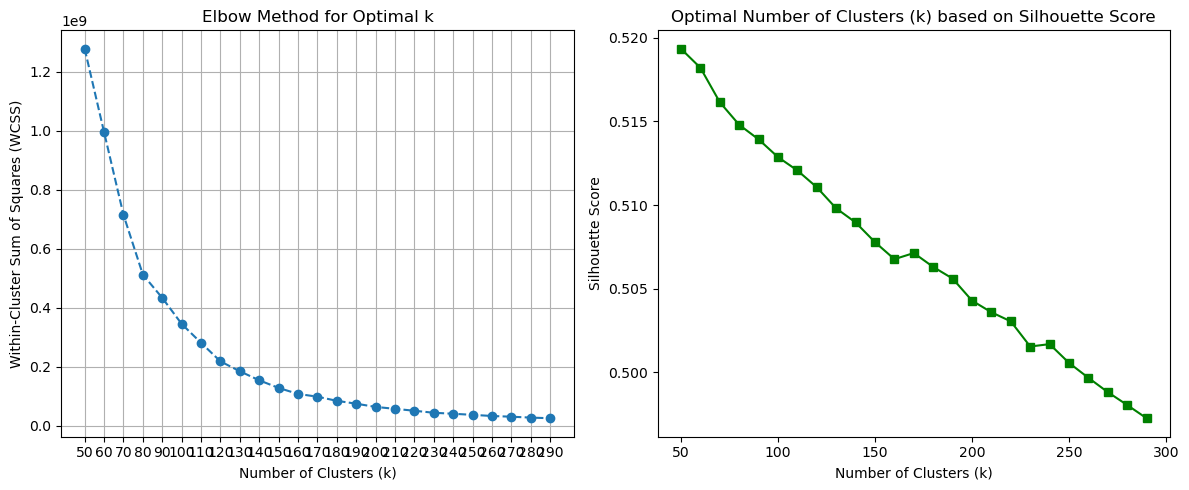

CPU times: user 6min 45s, sys: 31min 36s, total: 38min 22s
Wall time: 12min 13s


In [15]:
%%time

# Elbow Method
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score 

# Define range of clusters to test
cluster_range = range(50, 300, 10)
wcss = []
silhouette_scores = []

# Loop through different cluster numbers
for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    kmeans.fit(cp.asarray(reduced_data))
    wcss.append(kmeans.inertia_)

    labels = kmeans.labels_
    s = silhouette_score(reduced_data, labels)
    silhouette_scores.append(s)

# --- Plot Results ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# WSSE Plot 
axes[0].plot(cluster_range, wcss, marker='o', linestyle='--')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Within-Cluster Sum of Squares (WCSS)')
axes[0].set_title('Elbow Method for Optimal k')
axes[0].set_xticks(cluster_range)
axes[0].grid(True)

# Silhouette Score Plot
axes[1].plot(cluster_range, silhouette_scores, marker='s', linestyle='-', color='g')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Optimal Number of Clusters (k) based on Silhouette Score')

plt.tight_layout()
plt.show()

Apply K-Means Clustering

In [16]:
%%time

# Apply KMeans Clustering on Reduced Data
n_clusters = 150  # Number of clusters to form
kmeans_model = KMeans(
    n_clusters=n_clusters,
    max_iter=300,           # Maximum number of iterations for convergence
    init='k-means++',       # Smart initialization of centroids
    random_state=42,        # For reproducibility
    n_init = 10
)

# Fit the KMeans model and predict cluster labels
cluster_labels = kmeans_model.fit_predict(cp.asarray(reduced_data))  # Use cupy arrays for GPU acceleration

[2025-08-18 04:56:04.283] [CUML] [debug] cuML: Performing fit_predict in GPU
[2025-08-18 04:56:04.284] [CUML] [debug] cuML: Performing fit in GPU
CPU times: user 3.02 s, sys: 46.2 ms, total: 3.07 s
Wall time: 3.06 s


Reduce Dimensionality to 3D using UMAP

In [17]:
%%time

# Reduce dimensionality to 3D using cuML UMAP
umap_3d = UMAP(n_neighbors = 15, min_dist = 0.1, n_components = 3)
embedding_3d = umap_3d.fit_transform(cp.asarray(reduced_data))

[2025-08-18 04:56:07.794] [CUML] [info] Building knn graph using brute force
CPU times: user 433 ms, sys: 36.3 ms, total: 470 ms
Wall time: 772 ms


In [18]:
# Convert GPU arrays back to NumPy for Plotly
embedding_3d_cpu = cp.asnumpy(embedding_3d)
cluster_labels_cpu = cp.asnumpy(cluster_labels)

Create Interactive 3D Scatter Plot using Plotly

In [19]:
# Create interactive 3D Scatter Plot using Plotly
fig = px.scatter_3d(
    x = embedding_3d_cpu[:, 0], 
    y = embedding_3d_cpu[:, 1],
    z = embedding_3d_cpu[:, 2],
    color = cluster_labels_cpu.astype(str), # Convert labels to stirng for coloring
    title = "Interactive 3D Scatter Plot of K-Means Cluster",
    labels = {"color": "Cluster"}
)

# Customize the plot
fig.update_traces(marker = dict(size = 5)) # Adjust marker size
fig.update_layout(
    scene = dict(
        xaxis_title = "UMAP Component 1",
        yaxis_title = "UMAP Component 2",
        zaxis_title = "UMAP Component 3",
    ),
    margin = dict(l=0, r=0, b=0, t=40), # Reduce margins for a cleaner look
)

# Show the plot
fig.show()

## cuML HDBSCAN

Identify the Optimal Value for min_cluster_sizes

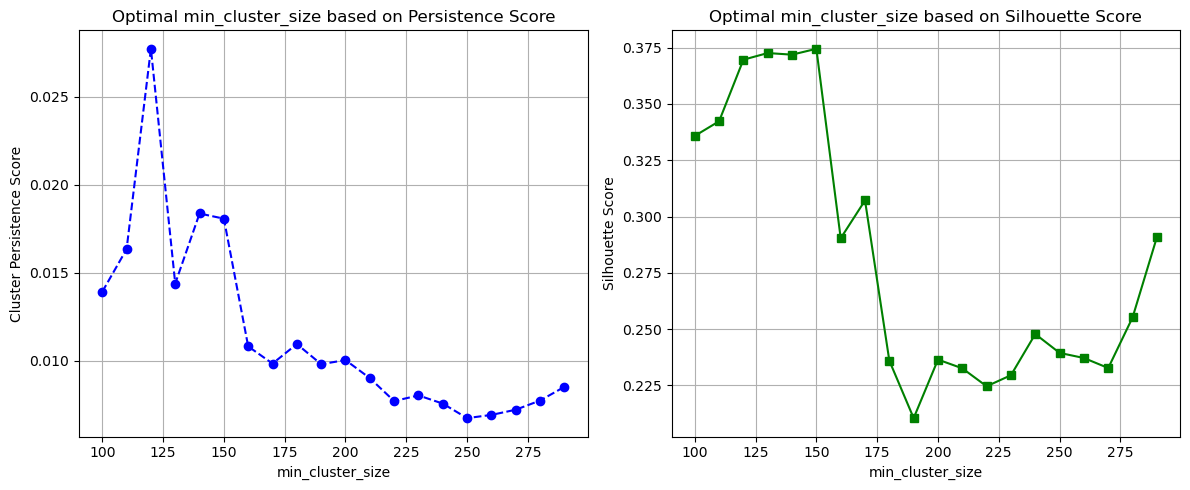

In [20]:
from hdbscan import HDBSCAN
from sklearn.metrics import silhouette_score

# Try different `min_cluster_size` values
min_cluster_sizes = range(100, 300, 10)
persistence_scores = []
silhouette_scores = []

for size in min_cluster_sizes:
    clusterer = HDBSCAN(min_cluster_size=size)
    clusterer.fit(cp.asarray(reduced_data))
    p = clusterer.cluster_persistence_
    persistence_scores.append(cp.mean(p).item())  # Measures cluster validity

    labels = clusterer.labels_
    s = silhouette_score(reduced_data, labels)
    silhouette_scores.append(s)

# --- Plot Results ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Persistence Score Plot
axes[0].plot(min_cluster_sizes, persistence_scores, marker='o', linestyle='--', color='b')
axes[0].set_xlabel('min_cluster_size')
axes[0].set_ylabel('Cluster Persistence Score')
axes[0].set_title('Optimal min_cluster_size based on Persistence Score')
axes[0].grid(True)

# Silhouette Score Plot
axes[1].plot(min_cluster_sizes, silhouette_scores, marker='s', linestyle='-', color='g')
axes[1].set_xlabel('min_cluster_size')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Optimal min_cluster_size based on Silhouette Score')
axes[1].grid(True)

plt.tight_layout()
plt.show()

Cluster Persistence Score and Silhouette Score graphs indicate HDBSCAN is not a fit Clustering model for this dataset. 

Apply HDBSCAN Clustering

In [21]:
from cuml.cluster import HDBSCAN

# Perform HDBSCAN Clustering using cuML
hdbscan = HDBSCAN(min_samples=10, min_cluster_size=200, gen_min_span_tree=True)
hdbscan.fit(cp.asarray(reduced_data))

# Extract cluster labels
cluster_labels = hdbscan.labels_

In [22]:
# Convert GPU arrays back to NumPy for Plotly visualization
embedding_3d_cpu = cp.asnumpy(reduced_data)
cluster_labels_cpu = cp.asnumpy(cluster_labels)

Create Interactive 3D Scatter Plot using Plotly

In [23]:
# Create interactive 3D Scatter Plot using Plotly
fig = px.scatter_3d(
    x = embedding_3d_cpu[:, 0], 
    y = embedding_3d_cpu[:, 1],
    z = embedding_3d_cpu[:, 2],
    color = cluster_labels_cpu.astype(str), # Convert labels to stirng for coloring
    title = "Interactive 3D Scatter Plot of K-Means Cluster",
    labels = {"color": "Cluster"}
)

# Customize the plot
fig.update_traces(marker = dict(size = 5)) # Adjust marker size
fig.update_layout(
    scene = dict(
        xaxis_title = "UMAP Component 1",
        yaxis_title = "UMAP Component 2",
        zaxis_title = "UMAP Component 3",
    ),
    # margin = dict(l=0, r=0, b=0, t=40), # Reduce margins for a cleaner look
)

# Show the plot
fig.show()

**Well Done!**

<img src="images/nvidia_header.png" style="margin-left: -30px; width: 300px; float: left;">